# PRCP-1016 Heart Disease Prediction

## Introduction

The Heart Disease Prediction project aims to develop a machine learning model that can predict the likelihood of heart disease based on patients' medical information. Various machine learning algorithms are applied and compared to identify the model that provides the best predictive performance. The project also focuses on analysing important health factors and providing suggestions that may help hospitals improve early detection and patient care.

## 1. Import libraries

In [47]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.naive_bayes import GaussianNB

from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix,
                             classification_report, ConfusionMatrixDisplay)


import joblib
RANDOM_STATE = 42
sns.set_theme(style='whitegrid')

## 2. Loading CSV files

In [48]:
values = pd.read_csv(r'C:\Users\D E L L\Desktop\Yuvan Shankar. Python\AI\Datasets\heart disease dataset\Data\values.csv')
labels = pd.read_csv(r'C:\Users\D E L L\Desktop\Yuvan Shankar. Python\AI\Datasets\heart disease dataset\Data\labels.csv')

print('Values shape:', values.shape)
print('Labels shape:', labels.shape)

Values shape: (180, 14)
Labels shape: (180, 2)


In [49]:
assert values['patient_id'].is_unique
assert labels['patient_id'].is_unique
assert set(values['patient_id']) == set(labels['patient_id'])

In [50]:
df = pd.merge(values, labels, on='patient_id')
TARGET = 'heart_disease_present'

print('Combined shape:', df.shape)
display(df.head())

Combined shape: (180, 15)


,patient_id,slope_of_peak_exercise_st_segment,thal,resting_blood_pressure,chest_pain_type,num_major_vessels,fasting_blood_sugar_gt_120_mg_per_dl,resting_ekg_results,serum_cholesterol_mg_per_dl,oldpeak_eq_st_depression,sex,age,max_heart_rate_achieved,exercise_induced_angina,heart_disease_present
0,0z64un,1,normal,128,2,0,0,2,308,0.0,1,45,170,0,0
1,ryoo3j,2,normal,110,3,0,0,0,214,1.6,0,54,158,0,0
2,yt1s1x,1,normal,125,4,3,0,2,304,0.0,1,77,162,1,1
3,l2xjde,1,reversible_defect,152,4,0,0,0,223,0.0,1,40,181,0,1
4,oyt4ek,3,reversible_defect,178,1,0,0,2,270,4.2,1,59,145,0,0


## 3. Understanding the dataset

In [51]:
print('Rows and columns:', df.shape)
print('\nColumn names:')
print(df.columns.tolist())

print('\nData types and non-null counts:')
df.info()

Rows and columns: (180, 15)

Column names:
['patient_id', 'slope_of_peak_exercise_st_segment', 'thal', 'resting_blood_pressure', 'chest_pain_type', 'num_major_vessels', 'fasting_blood_sugar_gt_120_mg_per_dl', 'resting_ekg_results', 'serum_cholesterol_mg_per_dl', 'oldpeak_eq_st_depression', 'sex', 'age', 'max_heart_rate_achieved', 'exercise_induced_angina', 'heart_disease_present']

Data types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 180 entries, 0 to 179
Data columns (total 15 columns):
 #   Column                                Non-Null Count  Dtype  
---  ------                                --------------  -----  
 0   patient_id                            180 non-null    object 
 1   slope_of_peak_exercise_st_segment     180 non-null    int64  
 2   thal                                  180 non-null    object 
 3   resting_blood_pressure                180 non-null    int64  
 4   chest_pain_type                       180 non-null    int64  
 5   num_

In [52]:
print('Missing values in each column:')
display(df.isnull().sum())

print('Duplicate rows:', df.duplicated().sum())
print('Duplicate patient IDs:', df['patient_id'].duplicated().sum())

print('\nSummary statistics:')
display(df.describe(include='all').T)

Missing values in each column:


patient_id                              0
slope_of_peak_exercise_st_segment       0
thal                                    0
resting_blood_pressure                  0
chest_pain_type                         0
num_major_vessels                       0
fasting_blood_sugar_gt_120_mg_per_dl    0
resting_ekg_results                     0
serum_cholesterol_mg_per_dl             0
oldpeak_eq_st_depression                0
sex                                     0
age                                     0
max_heart_rate_achieved                 0
exercise_induced_angina                 0
heart_disease_present                   0
dtype: int64

Duplicate rows: 0
Duplicate patient IDs: 0

Summary statistics:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
patient_id,180,180,0z64un,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
slope_of_peak_exercise_st_segment,180.0,NaN,NaN,NaN,1.55,0.618838,1.0,1.0,1.0,2.0,3.0
thal,180,3,normal,98,NaN,NaN,NaN,NaN,NaN,NaN,NaN
resting_blood_pressure,180.0,NaN,NaN,NaN,131.311111,17.010443,94.0,120.0,130.0,140.0,180.0
chest_pain_type,180.0,NaN,NaN,NaN,3.155556,0.938454,1.0,3.0,3.0,4.0,4.0
num_major_vessels,180.0,NaN,NaN,NaN,0.694444,0.969347,0.0,0.0,0.0,1.0,3.0
fasting_blood_sugar_gt_120_mg_per_dl,180.0,NaN,NaN,NaN,0.161111,0.368659,0.0,0.0,0.0,0.0,1.0
resting_ekg_results,180.0,NaN,NaN,NaN,1.05,0.998742,0.0,0.0,2.0,2.0,2.0
serum_cholesterol_mg_per_dl,180.0,NaN,NaN,NaN,249.211111,52.717969,126.0,213.75,245.5,281.25,564.0
oldpeak_eq_st_depression,180.0,NaN,NaN,NaN,1.01,1.121357,0.0,0.0,0.8,1.6,6.2


## 4. Exploratory Data Analysis (EDA)

heart_disease_present
0    100
1     80
Name: count, dtype: int64


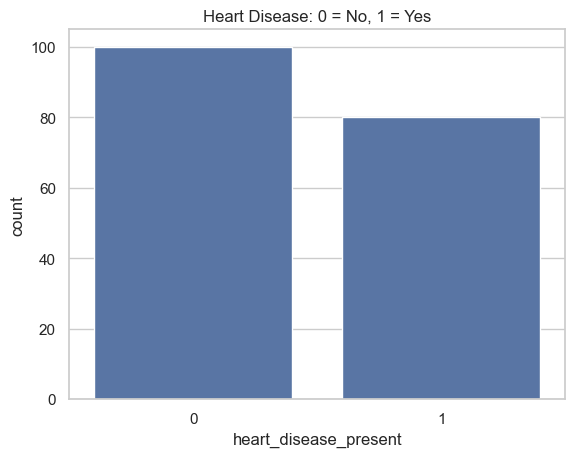

In [53]:
print(df[TARGET].value_counts())

sns.countplot(data=df, x=TARGET)
plt.title('Heart Disease: 0 = No, 1 = Yes')
plt.show()

### 4.1 Numerical columns

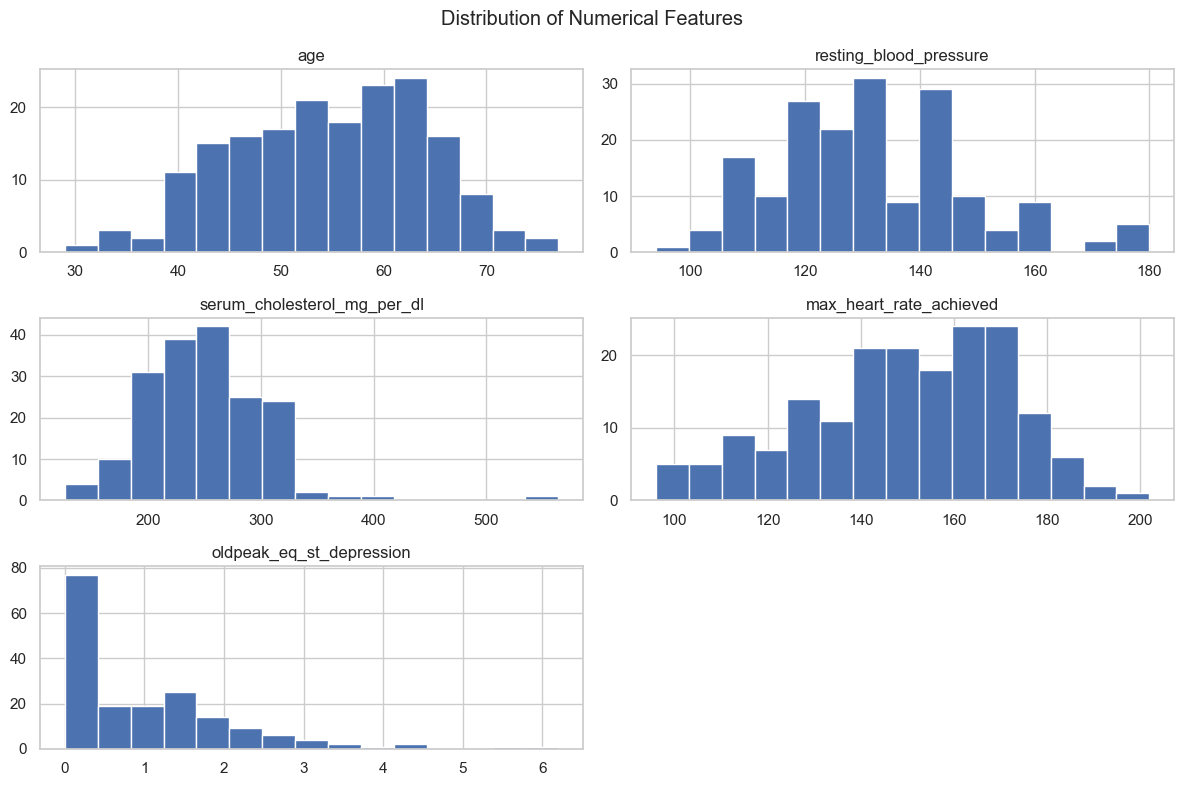

In [54]:
numeric_cols = [
    'age',
    'resting_blood_pressure',
    'serum_cholesterol_mg_per_dl',
    'max_heart_rate_achieved',
    'oldpeak_eq_st_depression'
]

df[numeric_cols].hist(figsize=(12, 8), bins=15)
plt.suptitle('Distribution of Numerical Features')
plt.tight_layout()
plt.show()

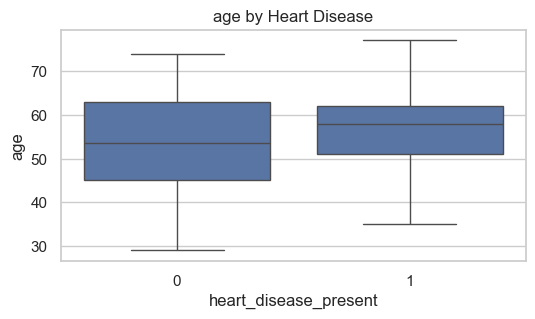

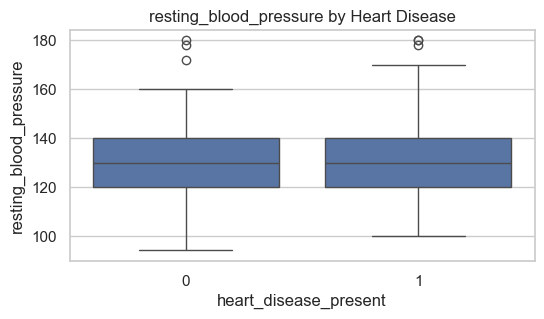

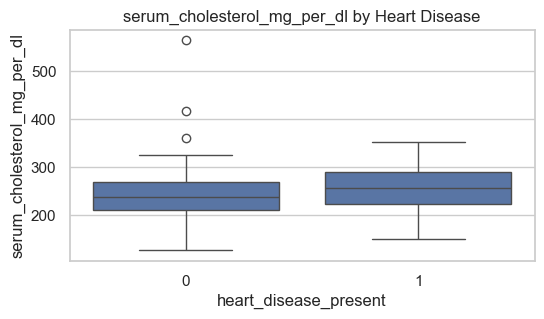

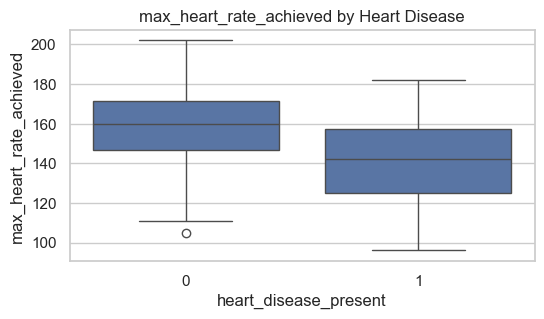

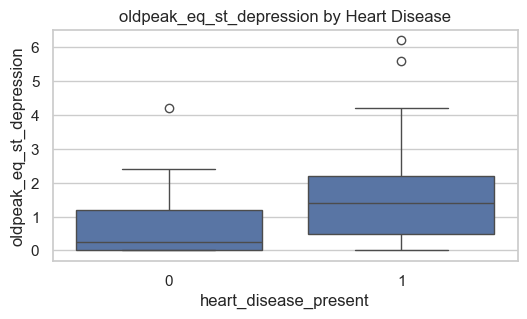

In [55]:
for col in numeric_cols:
    plt.figure(figsize=(6, 3))
    sns.boxplot(data=df, x=TARGET, y=col)
    plt.title(col + ' by Heart Disease')
    plt.show()

### 4.2 Categorical feature counts by target

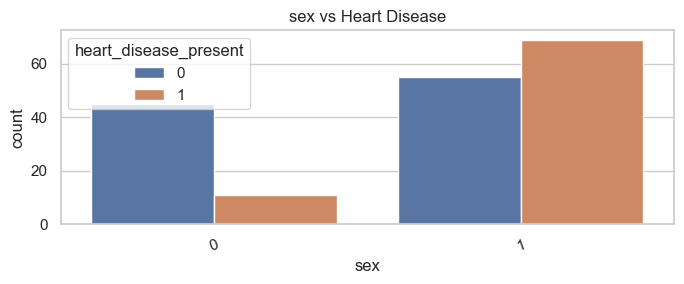

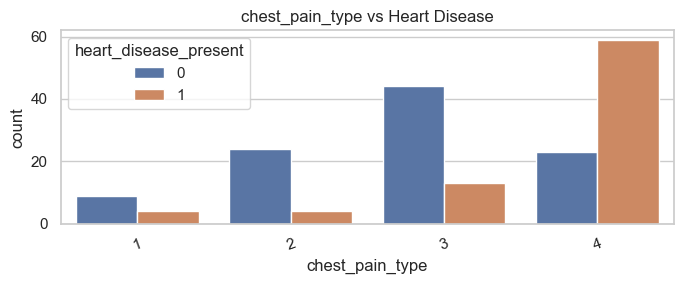

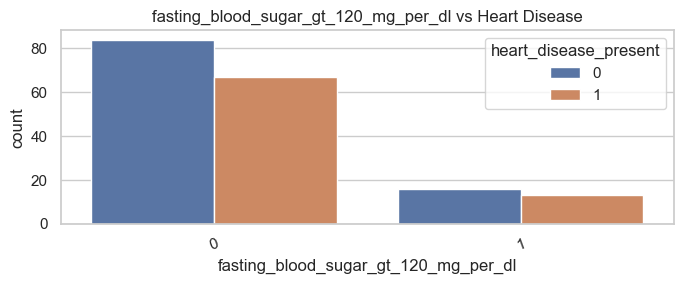

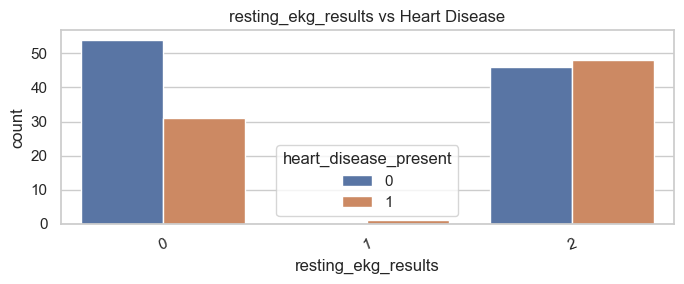

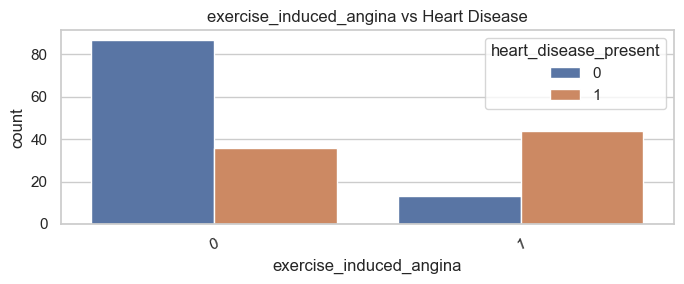

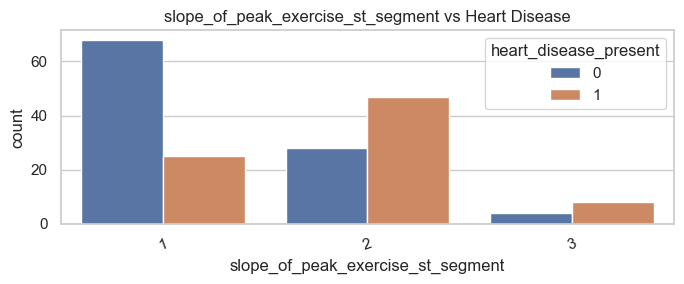

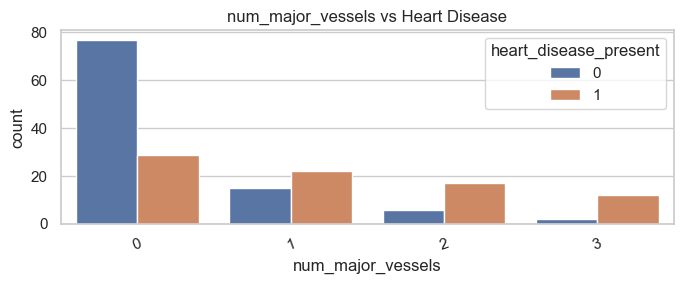

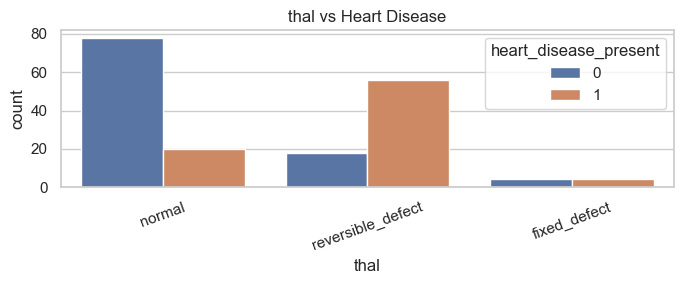

In [56]:
categorical_cols = [
    'sex',
    'chest_pain_type',
    'fasting_blood_sugar_gt_120_mg_per_dl',
    'resting_ekg_results',
    'exercise_induced_angina',
    'slope_of_peak_exercise_st_segment',
    'num_major_vessels',
    'thal'
]

for col in categorical_cols:
    plt.figure(figsize=(7, 3))
    sns.countplot(data=df, x=col, hue=TARGET)
    plt.title(col + ' vs Heart Disease')
    plt.xticks(rotation=20)
    plt.tight_layout()
    plt.show()

### 4.3 Correlation heatmap

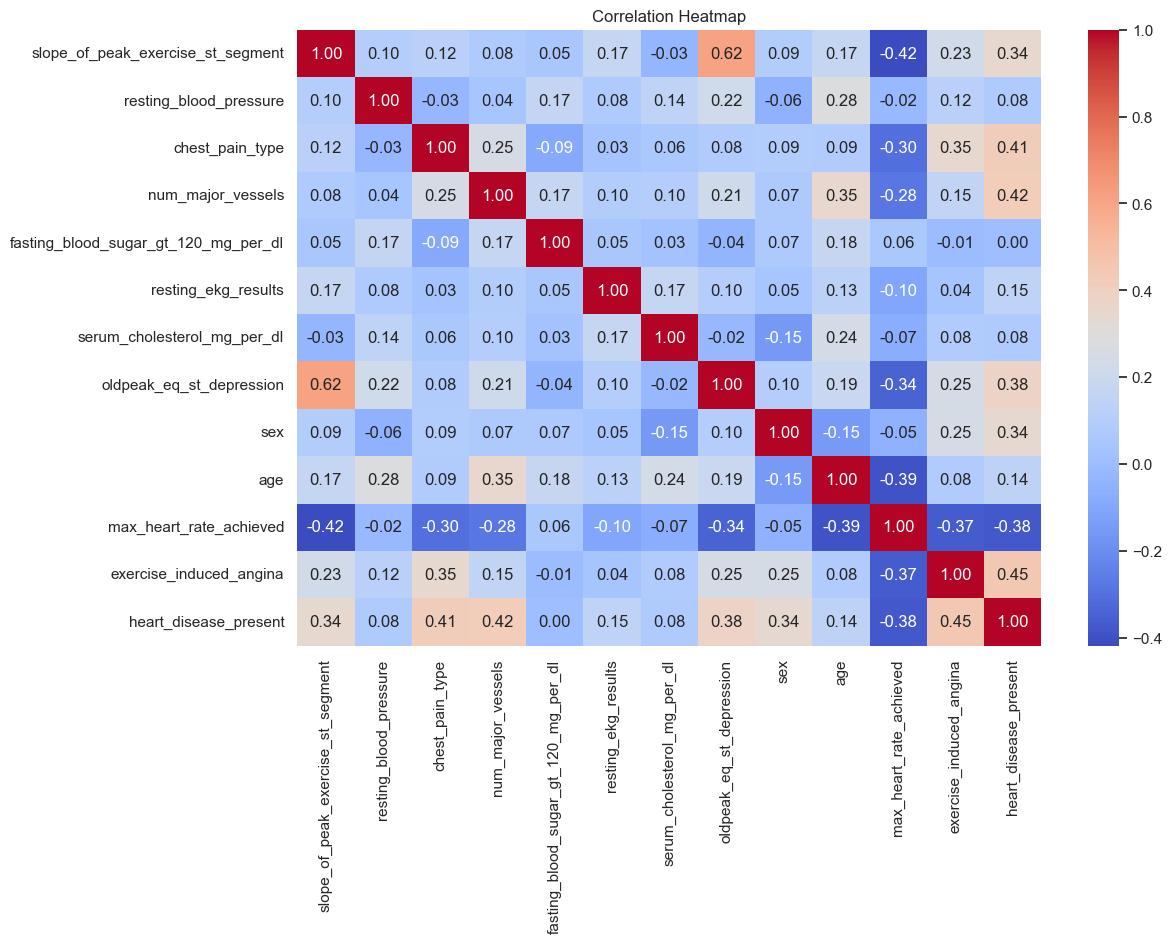

In [57]:
plt.figure(figsize=(12, 8))
sns.heatmap(df.select_dtypes(include='number').corr(),
            annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap')
plt.show()

### 4.4 EDA Observations

After performing Exploratory Data Analysis (EDA) on the Heart Disease dataset, several important observations were identified. These observations help us understand the distribution of patient information, relationships between medical features and the presence of heart disease.

#### 1. Target Variable Distribution

- The dataset contains 180 patient records.
- 100 patients (55.56%) do not have heart disease.
- 80 patients (44.44%) have heart disease.
- The target variable is relatively balanced, with a small difference between the two classes.

**Observation:** The dataset does not have a severe class imbalance. Therefore, stratified train-test splitting and classification evaluation metrics can be used to assess model performance.

#### 2. Age Distribution

- The age distribution shows that patients belong to different age groups.
- The boxplot indicates that the median age of patients with heart disease is slightly higher than that of patients without heart disease.
- Both groups contain patients across a relatively wide age range.

**Observation:** Age may contribute to heart disease prediction, although it should not be considered an independent indicator of heart disease.

#### 3. Resting Blood Pressure

- Resting blood pressure values vary across patients.
- The boxplots show similar median resting blood pressure values for patients with and without heart disease.
- Some unusually high blood pressure observations are visible in both groups.

**Observation:** Resting blood pressure alone does not clearly distinguish between the two target classes. However, it remains an important clinical feature for evaluating cardiovascular risk.

#### 4. Serum Cholesterol

- Serum cholesterol levels show considerable variation among patients.
- Patients with heart disease appear to have a slightly higher median cholesterol level.
- Some unusually high cholesterol observations are present in the dataset.

**Observation:** Cholesterol may contribute to heart disease prediction, but its relationship with the target variable is not particularly strong in the correlation analysis.

#### 5. Maximum Heart Rate Achieved

- Patients without heart disease generally show higher maximum heart rate values.
- Patients with heart disease have a comparatively lower median maximum heart rate.
- The boxplot indicates a noticeable difference between the two groups.

**Observation:** Maximum heart rate achieved during exercise appears to be an important feature for distinguishing between patients with and without heart disease.

#### 6. ST Depression (Oldpeak)

- Patients with heart disease generally show higher ST depression values.
- The median Oldpeak value is noticeably higher in the heart disease group.
- Some higher-value observations are also visible.

**Observation:** ST depression appears to have an important relationship with heart disease and may help the machine learning model identify potential positive cases.

#### 7. Chest Pain Type

- Chest pain type 4 has a comparatively higher number of patients with heart disease.
- Chest pain types 2 and 3 contain more patients without heart disease.
- The distribution of heart disease varies considerably across chest pain categories.

**Observation:** Chest pain type appears to be an important categorical feature for predicting heart disease.

#### 8. Thalassemia (Thal)

- Patients with normal thal results are more frequently represented in the group without heart disease.
- Patients with reversible defects are more frequently represented in the heart disease group.
- Fixed defects have relatively fewer observations in the dataset.

**Observation:** Thal results appear to have a strong relationship with heart disease and may provide useful information for classification.

#### 9. Exercise-Induced Angina

- Patients experiencing exercise-induced angina show a higher representation of heart disease cases.
- Patients without exercise-induced angina contain a comparatively higher number of individuals without heart disease.

**Observation:** Exercise-induced angina appears to be an important indicator associated with heart disease in this dataset.

#### 10. Correlation Analysis

The correlation heatmap provides insights into the linear relationships between numerical features.

The following observations were identified:

- Exercise-induced angina has a positive correlation of approximately 0.45 with heart disease.
- Number of major vessels has a positive correlation of approximately 0.42.
- Chest pain type has a positive correlation of approximately 0.41.
- ST depression (Oldpeak) has a positive correlation of approximately 0.38.
- Slope of peak exercise ST segment has a positive correlation of approximately 0.34.
- Sex has a positive correlation of approximately 0.34.
- Maximum heart rate achieved has a negative correlation of approximately -0.38.
- Age has a relatively weak positive correlation of approximately 0.14.
- Fasting blood sugar has almost no linear correlation with the target variable.

**Observation:** Exercise-induced angina, number of major vessels, chest pain type and ST depression show relatively stronger positive correlations with heart disease. Maximum heart rate achieved shows a negative correlation.

It is important to note that correlation measures linear association and does not establish causation. A low correlation does not necessarily mean that a feature is unimportant for machine learning prediction.

#### 11. Overall EDA Findings

Based on the exploratory data analysis, the following conclusions were obtained:

1. The dataset contains 180 patient records with a relatively balanced target distribution.
2. Maximum heart rate and ST depression show noticeable differences between patients with and without heart disease.
3. Chest pain type and thal results demonstrate different distributions across the target classes.
4. Exercise-induced angina appears frequently among patients with heart disease.
5. Number of major vessels shows a positive relationship with heart disease.
6. Resting blood pressure and cholesterol alone do not clearly separate the two target groups.
7. Certain numerical features contain unusually high observations, which should be examined carefully rather than removed without medical justification.

#### Final EDA Conclusion

The exploratory data analysis indicates that several medical features have meaningful relationships with the presence of heart disease. Features such as exercise-induced angina, chest pain type, number of major vessels, ST depression, thal results and maximum heart rate may contribute significantly to prediction.

These findings provide a foundation for the next stage of the project, where multiple machine learning classification algorithms are trained and evaluated to identify the most suitable model for heart disease prediction.

## 5. Prepare data for Machine Learning

In [58]:
X = df.drop(columns=['patient_id', TARGET])
y = df[TARGET]

numeric_features = [
    'age',
    'resting_blood_pressure',
    'serum_cholesterol_mg_per_dl',
    'max_heart_rate_achieved',
    'oldpeak_eq_st_depression'
]

categorical_features = [col for col in X.columns if col not in numeric_features]

try:
    encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
except TypeError:
    encoder = OneHotEncoder(handle_unknown='ignore', sparse=False)

preprocessor = ColumnTransformer(
    transformers=[
        ('numeric', StandardScaler(), numeric_features),
        ('categorical', encoder, categorical_features)
    ],
    remainder='drop'
)

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print('Training rows:', X_train.shape[0])
print('Testing rows:', X_test.shape[0])

Training rows: 144
Testing rows: 36


## 6. Build and compare Machine Learning models

In [59]:
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000),
    'KNN': KNeighborsClassifier(n_neighbors=5),
    'SVM': SVC(probability=True, random_state=RANDOM_STATE),
    'Decision Tree': DecisionTreeClassifier(random_state=RANDOM_STATE),
    'Random Forest': RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE),
    'Gradient Boosting': GradientBoostingClassifier(random_state=RANDOM_STATE),
    'Naive Bayes': GaussianNB()
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

scoring = {
    'accuracy': 'accuracy',
    'precision': 'precision',
    'recall': 'recall',
    'f1': 'f1',
    'roc_auc': 'roc_auc'
}

results = []
pipelines = {}

for name, model in models.items():
    pipe = Pipeline(steps=[
        ('preprocessing', preprocessor),
        ('model', model)
    ])

    scores = cross_validate(
        pipe, X_train, y_train,
        cv=cv,
        scoring=scoring
    )

    pipelines[name] = pipe

    results.append({
        'Model': name,
        'CV Accuracy': scores['test_accuracy'].mean(),
        'CV Precision': scores['test_precision'].mean(),
        'CV Recall': scores['test_recall'].mean(),
        'CV F1': scores['test_f1'].mean(),
        'CV ROC-AUC': scores['test_roc_auc'].mean()
    })

results_df = pd.DataFrame(results).sort_values(
    by='CV ROC-AUC', ascending=False
).reset_index(drop=True)

display(results_df.round(3))

,Model,CV Accuracy,CV Precision,CV Recall,CV F1,CV ROC-AUC
0,SVM,0.813,0.811,0.782,0.787,0.864
1,Logistic Regression,0.792,0.812,0.735,0.760,0.864
2,Random Forest,0.778,0.768,0.751,0.751,0.864
3,Gradient Boosting,0.777,0.747,0.782,0.758,0.861
4,Naive Bayes,0.813,0.819,0.765,0.782,0.846
5,KNN,0.784,0.783,0.735,0.750,0.832
6,Decision Tree,0.736,0.683,0.765,0.718,0.739


## 6.1 Model Comparison Report

To identify the most suitable machine learning algorithm for predicting heart disease, seven classification models were implemented and evaluated.

The following models were compared:

1. Logistic Regression
2. K-Nearest Neighbors (KNN)
3. Support Vector Machine (SVM)
4. Decision Tree
5. Random Forest
6. Gradient Boosting
7. Naive Bayes

### 1. Model Evaluation

The models were evaluated using 5-fold cross-validation. The following performance metrics were considered:

- **Accuracy:** Measures the overall percentage of correct predictions.
- **Precision:** Measures how many predicted positive cases were actually positive.
- **Recall:** Measures how many actual positive cases were correctly identified.
- **F1-Score:** Represents the balance between precision and recall.
- **ROC-AUC:** Measures the model's ability to distinguish between positive and negative classes.

### 2. Model Comparison Table

| Model | Accuracy | Precision | Recall | F1-Score | ROC-AUC |
|---|---:|---:|---:|---:|---:|
| SVM | 81.3% | 81.1% | 78.2% | 78.7% | 86.4% |
| Logistic Regression | 79.2% | 81.2% | 73.5% | 76.0% | 86.4% |
| Random Forest | 77.8% | 76.8% | 75.1% | 75.1% | 86.4% |
| Gradient Boosting | 77.7% | 74.7% | 78.2% | 75.8% | 86.1% |
| Naive Bayes | 81.3% | 81.9% | 76.5% | 78.2% | 84.6% |
| KNN | 78.4% | 78.3% | 73.5% | 75.0% | 83.2% |
| Decision Tree | 73.6% | 68.3% | 76.5% | 71.8% | 73.9% |

### 3. Observations

- **SVM** achieved an accuracy of 81.3% and an ROC-AUC score of 86.4%, making it one of the strongest overall models.
- **Naive Bayes** also achieved 81.3% accuracy and obtained the highest precision of 81.9%.
- **Logistic Regression** achieved an ROC-AUC score of 86.4%, showing good classification performance.
- **Random Forest** demonstrated balanced performance across several evaluation metrics.
- **Gradient Boosting** achieved a recall of 78.2%, indicating its ability to identify positive cases.
- **KNN** provided reasonable performance but did not outperform the leading models.
- **Decision Tree** achieved the lowest accuracy and ROC-AUC score among the evaluated models.

### 4. Best Model Selection

Based on the cross-validation results, Support Vector Machine (SVM) was selected as the preferred candidate because it achieved a strong combination of accuracy, F1-score, and ROC-AUC.

SVM achieved an ROC-AUC score of 86.4%, which was also achieved by Logistic Regression and Random Forest. Therefore, SVM was selected based on its overall performance rather than ROC-AUC alone.

### 5. SVM Test Performance

The selected SVM model was evaluated separately using the test dataset.

| Evaluation Metric | Test Score |
|---|---:|
| Accuracy | 91.7% |
| Precision | 84.2% |
| Recall | 100% |
| F1-Score | 91.4% |
| ROC-AUC | 96.2% |

The SVM model achieved 91.7% test accuracy and 100% recall. This means that it identified all heart disease cases in the test set.

However, the test dataset contains only 36 records. Therefore, these results should be considered preliminary and should be validated using a larger, independent dataset.

### 6. Final Conclusion

After comparing seven machine learning classification algorithms, Support Vector Machine (SVM) was selected as the preferred model for this heart disease prediction project.

The model demonstrated strong performance across multiple evaluation metrics. Its high recall on the test dataset is particularly encouraging because identifying potential heart disease cases is important for further medical assessment.

However, this model is intended for academic prediction purposes and should not be used as a standalone medical diagnostic system. Further validation using larger clinical datasets and expert medical evaluation is necessary before considering real-world hospital applications.

## 7. Selecting the best model and Evaluation

In [60]:
best_name = results_df.loc[0, 'Model']
best_model = pipelines[best_name]

best_model.fit(X_train, y_train)

y_pred = best_model.predict(X_test)
y_probability = best_model.predict_proba(X_test)[:, 1]

print('Selected model:', best_name)
print('Test Accuracy :', round(accuracy_score(y_test, y_pred), 3))
print('Test Precision:', round(precision_score(y_test, y_pred, zero_division=0), 3))
print('Test Recall   :', round(recall_score(y_test, y_pred, zero_division=0), 3))
print('Test F1-score :', round(f1_score(y_test, y_pred, zero_division=0), 3))
print('Test ROC-AUC  :', round(roc_auc_score(y_test, y_probability), 3))

print('\nClassification report:')
print(classification_report(y_test, y_pred, zero_division=0))

Selected model: SVM
Test Accuracy : 0.917
Test Precision: 0.842
Test Recall   : 1.0
Test F1-score : 0.914
Test ROC-AUC  : 0.962

Classification report:
              precision    recall  f1-score   support

           0       1.00      0.85      0.92        20
           1       0.84      1.00      0.91        16

    accuracy                           0.92        36
   macro avg       0.92      0.93      0.92        36
weighted avg       0.93      0.92      0.92        36



### 7.1 Confusion matrix

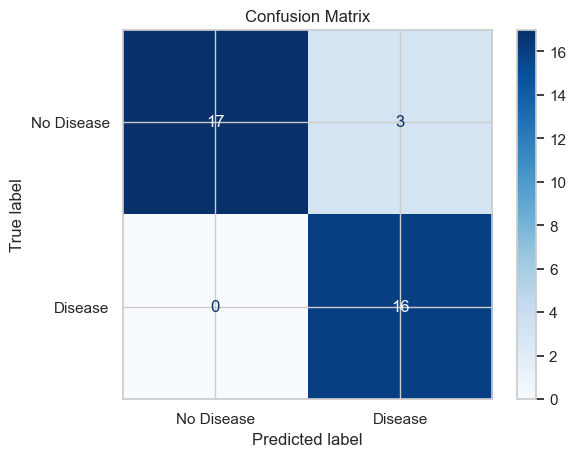

Rows = actual class; columns = predicted class.
False negatives are actual disease cases predicted as no disease.


In [61]:
cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['No Disease', 'Disease']
).plot(cmap='Blues')
plt.title('Confusion Matrix')
plt.show()

print('Rows = actual class; columns = predicted class.')
print('False negatives are actual disease cases predicted as no disease.')

### 7.2 Compare model performance 

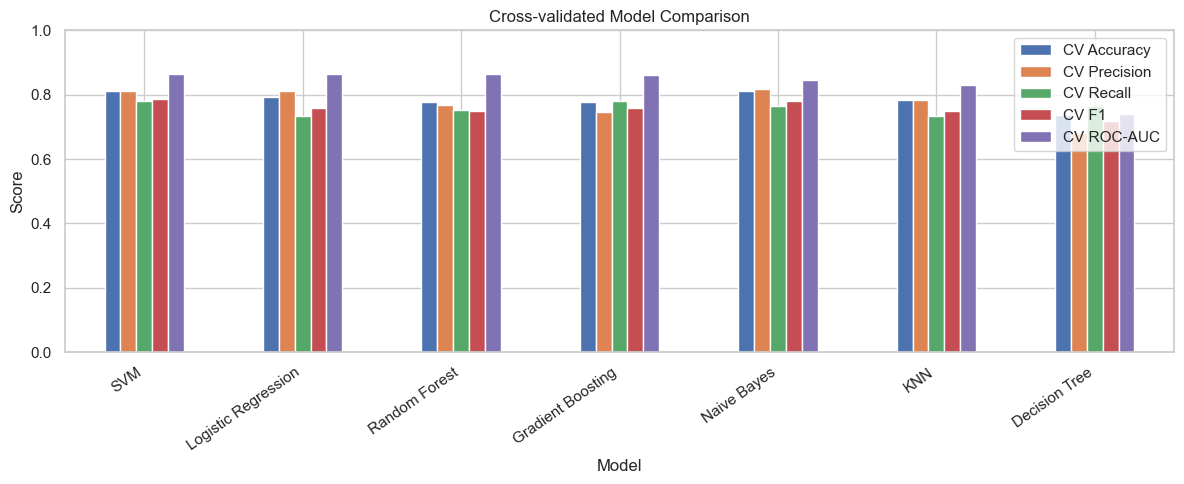

In [62]:
metrics = ['CV Accuracy', 'CV Precision', 'CV Recall', 'CV F1', 'CV ROC-AUC']

results_df.set_index('Model')[metrics].plot(
    kind='bar', figsize=(12, 5)
)
plt.title('Cross-validated Model Comparison')
plt.ylabel('Score')
plt.ylim(0, 1)
plt.xticks(rotation=35, ha='right')
plt.tight_layout()
plt.show()

## 8. Save the model

In [65]:
joblib.dump(best_model, "heart_disease_model.joblib")
print("Heart Disease Prediction Model saved")

Heart Disease Prediction Model saved


## 9. Model Performance with An Example

In [66]:
new_patient = pd.DataFrame([{
    'slope_of_peak_exercise_st_segment': 2,
    'thal': 'reversible_defect',
    'resting_blood_pressure': 140,
    'chest_pain_type': 4,
    'num_major_vessels': 2,
    'fasting_blood_sugar_gt_120_mg_per_dl': 0,
    'resting_ekg_results': 2,
    'serum_cholesterol_mg_per_dl': 260,
    'oldpeak_eq_st_depression': 2.0,
    'sex': 1,
    'age': 60,
    'max_heart_rate_achieved': 120,
    'exercise_induced_angina': 1
}])

saved_model = joblib.load('heart_disease_model.joblib')
prediction = saved_model.predict(new_patient)[0]
risk_score = saved_model.predict_proba(new_patient)[0, 1]

print('Predicted class:', prediction)
print('Model score for class 1:', round(risk_score, 3))

if prediction == 1:
    print('Model flags this record for clinical review.')
else:
    print('Model does not flag this record; this does NOT rule out disease.')

print('This example is educational and is not a diagnosis.')

Predicted class: 1
Model score for class 1: 0.98
Model flags this record for clinical review.
This example is educational and is not a diagnosis.


## 10 Challenges and solutions

| Challenge | Simple approach used |
|---|---|
| Features and labels are in separate files | Check patient IDs and merge using `patient_id` |
| Patient ID is not a medical feature | Drop it before training |
| Different measurement scales | Apply `StandardScaler` to numerical measurements |
| Categorical values | Apply one-hot encoding |
| Small dataset | Use stratified train/test split and 5-fold cross-validation |
| Model performance differs | Compare accuracy, precision, recall, F1 and ROC-AUC |
| Risk of missed positive cases | Review recall and false negatives carefully |

Only report a challenge as encountered if it is actually present in your data or workflow.


## 11 Challenges Faced with Techniques Used and Reason for Using the technique

| S.No | Challenges Faced | Technique Used | Reason for Using the Technique |
|---|---|---|---|
| 1 | Dataset features and target labels were provided separately. | Pandas Merge (`merge()`) | To combine the patient information and target labels using the common `patient_id` column. |
| 2 | Patient ID does not contribute to heart disease prediction. | Dropping Unnecessary Columns | Removed `patient_id` because it is a unique identifier and does not provide meaningful predictive information. |
| 3 | Dataset contained numerical and categorical features. | ColumnTransformer | To apply different preprocessing techniques to numerical and categorical columns within a single workflow. |
| 4 | Numerical features had different measurement scales. | StandardScaler | To standardize numerical features so that variables with larger scales do not dominate distance-based and margin-based algorithms. |
| 5 | Categorical variables could not be directly processed by certain machine learning algorithms. | OneHotEncoder | To convert categorical values into numerical representations without introducing an artificial ordinal relationship. |
| 6 | The dataset contained a relatively small number of patient records (180). | Stratified Train-Test Split and 5-Fold Cross-Validation | To maintain class proportions and obtain a more reliable estimate of model performance using different training and validation subsets. |
| 7 | Different machine learning algorithms produced different prediction results. | Model Comparison | To evaluate multiple classification algorithms and identify the most suitable model. |
| 8 | Accuracy alone was insufficient to evaluate healthcare predictions. | Precision, Recall, F1-Score and ROC-AUC | To evaluate different aspects of classification performance, particularly the model's ability to identify patients with potential heart disease. |
| 9 | Incorrectly classifying patients with heart disease as healthy could be dangerous. | Confusion Matrix and Recall Evaluation | To examine false negatives and assess how effectively the model identifies positive heart disease cases. |
| 10 | Preprocessing before cross-validation could introduce data leakage. | Scikit-learn Pipeline | To ensure that preprocessing steps are fitted independently within each training fold. |
| 11 | Selecting the best-performing classification algorithm was challenging. | ROC-AUC-Based Model Selection | To compare the models based on their ability to distinguish between positive and negative classes. |
| 12 | The trained model needed to be reused without retraining. | Joblib Serialization | To save the selected machine learning pipeline and reuse it for future predictions. |

## Suggestions to the hospital

1. Treat the model as an experimental screening-support tool, not a diagnostic system.
2. Have a qualified clinician review risk flags alongside symptoms, examination and established tests.
3. Do not use a low-risk model output to dismiss symptoms or delay urgent care.
4. Validate the model on a larger, independent and representative patient population before considering deployment.
5. Monitor false negatives, false positives and performance across relevant patient groups.
6. Protect patient information and follow applicable healthcare privacy and governance requirements.
7. Combine screening with evidence-based prevention, such as blood pressure and diabetes management, smoking cessation, healthy diet and physical activity.

## Conclusion

The Heart Disease Prediction project was successfully carried out to analyze patient health data and develop machine learning models capable of predicting the possibility of heart disease.

The dataset was explored and analyzed through Exploratory Data Analysis (EDA) to understand the distribution of medical attributes, identify important patterns, and examine relationships between different health indicators. Data preprocessing techniques, including feature encoding, standardization, and train-test splitting, were applied to prepare the dataset for model development.

Seven machine learning algorithms were implemented and evaluated: Logistic Regression, K-Nearest Neighbors, Support Vector Machine, Decision Tree, Random Forest, Gradient Boosting, and Naive Bayes. Based on the cross-validation results and overall performance, **Support Vector Machine (SVM) was selected as the preferred model**. It achieved 81.3% cross-validation accuracy and 86.4% ROC-AUC. On the test dataset, it achieved 91.7% accuracy, 100% recall, and 96.2% ROC-AUC.

The trained model was saved using Joblib and used to demonstrate predictions for new patient records. This project demonstrates how machine learning techniques can help identify potential heart disease cases and support early risk assessment.

Furthermore, the analysis highlights the importance of regular health check-ups, awareness of risk factors, healthy lifestyle choices, and early medical consultation. The developed model can serve as an academic prototype for exploring data-driven approaches to heart disease prediction.

**Overall, this project demonstrates the potential of machine learning in healthcare analytics. However, since the dataset is relatively small and the test results are based on only 36 records, further validation using larger and independent clinical datasets is necessary. The model should be considered a decision-support research prototype, not a replacement for professional medical diagnosis.**